In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress
import math

In [33]:
def plot_with_stats_table(x, y, xlabel, ylabel,
                          table_bbox=(0.05, 0.55, 0.50, 0.40),
                          watermark_loc=((0.95, 0.05), 'right', 'bottom'),
                          figsize=(8, 6),
                          plot_name=None,
                          slope_unit=''):
    """
    Black-square scatter + thin red regression line, Origin-style stats table,
    watermark. The 'Slope' row now includes `slope_unit`.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    slope, intercept, r_value, p_value, _ = linregress(x, y)
    r_squared = r_value ** 2
    n = len(x)
    adj_r_sq = 1 - (1 - r_squared) * (n - 1) / (n - 2) if n > 2 else float('nan')
    rss = np.sum((y - (slope * x + intercept)) ** 2)

    x_mean = np.mean(x)
    sxx = np.sum((x - x_mean) ** 2)
    if n > 2 and sxx > 0:
        s2 = rss / (n - 2)
        se_slope     = math.sqrt(s2 / sxx)
        se_intercept = math.sqrt(s2 * (1.0 / n + x_mean ** 2 / sxx))
    else:
        se_slope = se_intercept = 0.0

    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(x, y, 'ks', markersize=8)
    x_fit = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_fit, slope * x_fit + intercept, 'r-', linewidth=0.8)

    ax.set_xlabel(xlabel, fontsize=20)
    ax.set_ylabel(ylabel, fontsize=20)
    ax.tick_params(axis='both', which='major', labelsize=16)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    if np.max(np.abs(x)) >= 1e4:
        ax.ticklabel_format(style='sci', axis='x', scilimits=(0, 0))
    if np.max(np.abs(y)) >= 1e4:
        ax.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))

    unit_txt = f" {slope_unit}" if slope_unit else ""
    table_data = [
        ["Equation",                "y = a + b*x"],
        ["Plot",                    plot_name if plot_name else ylabel.split()[0]],
        ["Weight",                  "No Weighting"],
        ["Intercept",               f"{intercept:.5g} ± {se_intercept:.2g}"],
        ["Slope",                   f"{slope:.5g} ± {se_slope:.2g}{unit_txt}"],
        ["Residual Sum of Squares", f"{rss:.5g}"],
        ["Pearson's r",             f"{r_value:.5f}"],
        ["R-Square (COD)",          f"{r_squared:.5f}"],
        ["Adj. R-Square",           f"{adj_r_sq:.5f}"],
    ]

    table = ax.table(cellText=table_data, loc='upper left',
                     bbox=list(table_bbox), cellLoc='left')
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.2)

    ax.text(watermark_loc[0][0], watermark_loc[0][1],
            'Mohammad Javad Zhianpour\nBlack Body',
            transform=ax.transAxes,
            ha=watermark_loc[1], va=watermark_loc[2],
            fontsize=16)

    plt.tight_layout()
    plt.show()
    return slope, intercept, r_squared

In [34]:
# ------------------------------------------------------------------
# DISTANCE:  V_net vs 1/d²
# ------------------------------------------------------------------
data_distance = pd.DataFrame({
    'd_cm'     : [20,    25,    30,    35,    40,    45,    50,    55   ],
    'T_C'      : [354,   353,   348,   353,   348,   352,   354,   346  ],
    'V_off_mV' : [0.110, 0.090, 0.077, 0.082, 0.078, 0.071, 0.067, 0.063],
    'V_on_mV'  : [1.412, 0.912, 0.690, 0.515, 0.386, 0.332, 0.255, 0.210],
})
data_distance['inv_d2_cm2'] = 1.0 / data_distance['d_cm'] ** 2
data_distance['V_net_mV']   = data_distance['V_on_mV'] - data_distance['V_off_mV']

# ------------------------------------------------------------------
# ANGLE:  V_net vs cos(theta)
# ------------------------------------------------------------------
data_angle = pd.DataFrame({
    'theta_deg' : [10,    15,    20,    25,    30,    35,    40,    45,    50   ],
    'V_net_mV'  : [1.438, 1.377, 1.357, 1.266, 1.227, 1.146, 1.015, 0.885, 0.794],
})
data_angle['cos_theta'] = np.cos(np.deg2rad(data_angle['theta_deg']))

# ------------------------------------------------------------------
# TEMPERATURE:  V_net vs T^4
# ------------------------------------------------------------------
data_temp = pd.DataFrame({
    'T_C'      : [350,   339,   330,   319,   310,   300,   289,   280,   270  ],
    'V_off_mV' : [0.025, 0.025, 0.021, 0.016, 0.023, 0.022, 0.023, 0.025, 0.024],
    'V_on_mV'  : [0.650, 0.605, 0.572, 0.535, 0.504, 0.474, 0.445, 0.412, 0.380],
})
data_temp['T_K']      = data_temp['T_C'] + 273.0
data_temp['T4_K4']    = data_temp['T_K'] ** 4
data_temp['V_net_mV'] = data_temp['V_on_mV'] - data_temp['V_off_mV']

# ------------------------------------------------------------------
# ONE set of SI constants — used EVERYWHERE below
# ------------------------------------------------------------------
d_m       = 0.01    # aperture diameter [m]        (1 cm)
l_m       = 0.20    # source→thermopile distance [m] (20 cm)
S_V_per_W = 16.0    # sensitivity [V/W]  (= 16 mV/mW)

# Physical model (derivation in the final cell):
#   R(t)     = (4 d^2 / (pi l^4)) * P            [W/m^2]
#   P        = V_net / S                          [W]
#   R(t)     = sigma * T^4
# =>  slope of R(t) vs T^4  IS  sigma,  in W/(m^2·K^4).

In [35]:
data_distance

,d_cm,T_C,V_off_mV,V_on_mV,inv_d2_cm2,V_net_mV
0,20,354,0.110,1.412,0.002500,1.302
1,25,353,0.090,0.912,0.001600,0.822
2,30,348,0.077,0.690,0.001111,0.613
3,35,353,0.082,0.515,0.000816,0.433
4,40,348,0.078,0.386,0.000625,0.308
5,45,352,0.071,0.332,0.000494,0.261
6,50,354,0.067,0.255,0.000400,0.188
7,55,346,0.063,0.210,0.000331,0.147


In [26]:
data_angle

,theta [deg],cos(θ),V_net [mV]
0,10,0.984808,1.438
1,15,0.965926,1.377
2,20,0.939693,1.357
3,25,0.906308,1.266
4,30,0.866025,1.227
5,35,0.819152,1.146
6,40,0.766044,1.015
7,45,0.707107,0.885
8,50,0.642788,0.794


In [27]:
data_temp

,T [℃],T [K],T4 [K4],V_off [mV],V_on [mV],V_net [mV],R(t) [W/m^2]
0,350,623,150644120641,0.025,0.650,0.625,0.049736
1,339,612,140283207936,0.025,0.605,0.580,0.046155
2,330,603,132211504881,0.021,0.572,0.551,0.043847
3,319,592,122825015296,0.016,0.535,0.519,0.041301
4,310,583,115524532321,0.023,0.504,0.481,0.038277
5,300,573,107799932241,0.022,0.474,0.452,0.035969
6,289,562,99757432336,0.023,0.445,0.422,0.033582
7,280,553,93519144481,0.025,0.412,0.387,0.030796
8,270,543,86935932801,0.024,0.380,0.356,0.028330


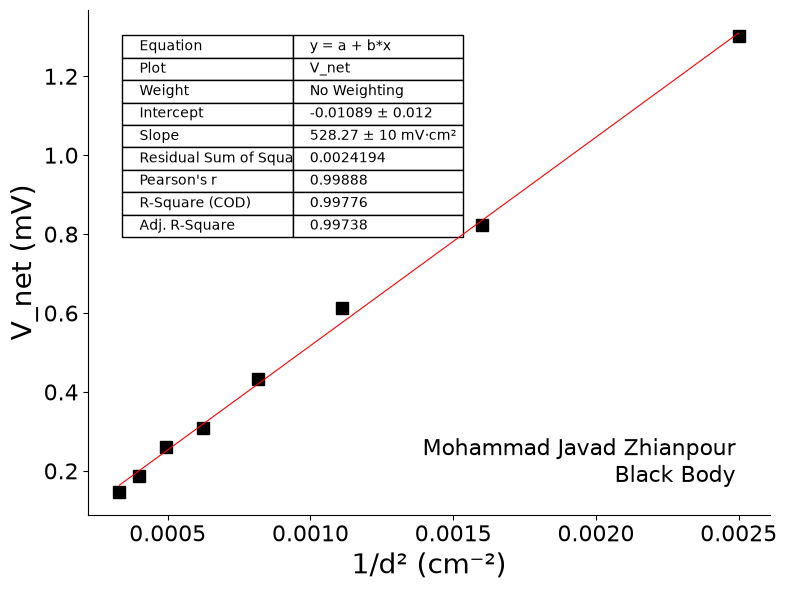

(np.float64(528.2727256490767),
 np.float64(-0.010890185915222728),
 np.float64(0.9977585515002276))

In [36]:
x = data_distance['inv_d2_cm2']
y = data_distance['V_net_mV']

plot_with_stats_table(
    x, y,
    xlabel='1/d² (cm⁻²)',
    ylabel='V_net (mV)',
    plot_name='V_net',
    slope_unit='mV·cm²',
    table_bbox=(0.05, 0.55, 0.50, 0.40),
    watermark_loc=((0.95, 0.05), 'right', 'bottom'),
)

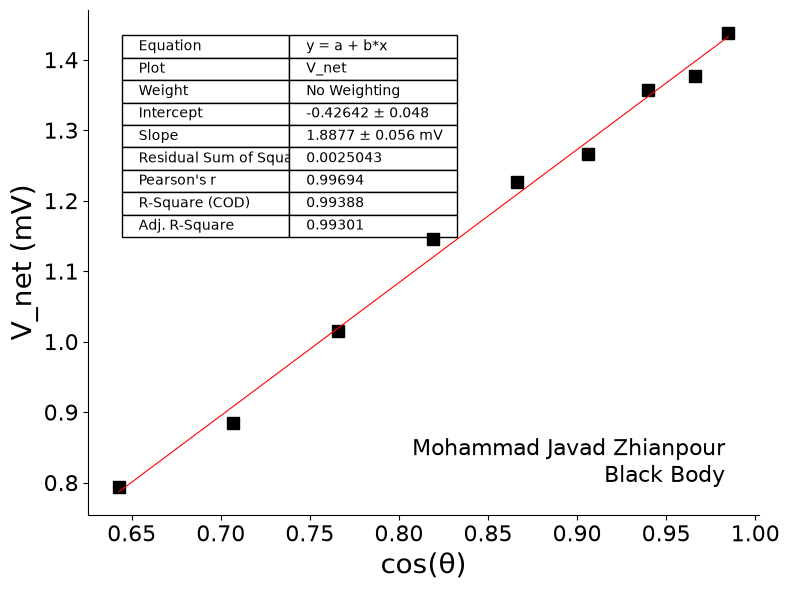

(np.float64(1.8877381547110685),
 np.float64(-0.4264168718811623),
 np.float64(0.9938804915811383))

In [37]:
x = data_angle['cos_theta']
y = data_angle['V_net_mV']

plot_with_stats_table(
    x, y,
    xlabel='cos(θ)',
    ylabel='V_net (mV)',
    plot_name='V_net',
    slope_unit='mV',
    table_bbox=(0.05, 0.55, 0.50, 0.40),
    watermark_loc=((0.95, 0.05), 'right', 'bottom'),
)

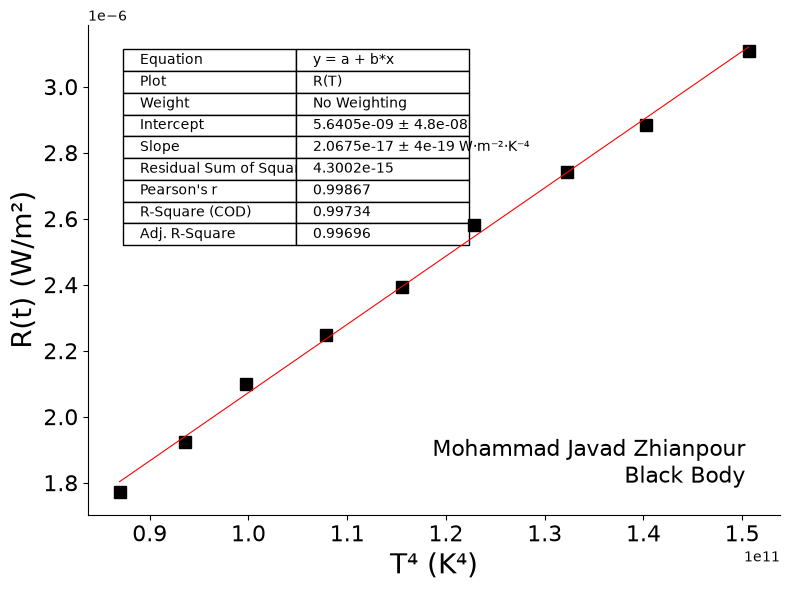

(np.float64(2.0675308148174424e-17),
 np.float64(5.640530664302801e-09),
 np.float64(0.9973439074210803))

In [38]:
# Compute R(t) once, with the SAME constants as everywhere else.
data_temp['V_net_V'] = data_temp['V_net_mV'] * 1e-3                # V
data_temp['P_W']     = data_temp['V_net_V'] / S_V_per_W            # W
data_temp['R_W_m2']  = (4 * d_m**2) / (np.pi * l_m**4) * data_temp['P_W']  # W/m²

x = data_temp['T4_K4']
y = data_temp['R_W_m2']یd

plot_with_stats_table(
    x, y,
    xlabel='T⁴ (K⁴)',
    ylabel='R(t) (W/m²)',
    plot_name='R(T)',
    slope_unit='W·m⁻²·K⁻⁴',   # the slope IS sigma, in these units
    table_bbox=(0.05, 0.55, 0.50, 0.40),
    watermark_loc=((0.95, 0.05), 'right', 'bottom'),
)